# Assignment 2 – Zero-Shot Image Classification with Transformers

In this assignment, you will apply a pre-trained vision–language transformer (e.g. CLIP) to perform **zero-shot** classification on the Fashion-MNIST dataset—classifying each image without any task-specific training. You will build on the concepts from Assignment 1 by comparing this “off-the-shelf” approach to the CNN you previously trained.

You will:
1. **Load** the Fashion-MNIST images using PyTorch instead of Keras.
2. **Run a zero-shot baseline** with simple text prompts to set a performance reference.
3. **Engineer improved prompts** and measure the resulting accuracy gains.
4. **Visualise image embeddings** with UMAP to inspect class separability.
5. **Conduct one mini-experiment** of your choice.
6. **Summarise findings** and reflect on strengths and weaknesses of zero-shot transformers versus a trained CNN.

# 1. Loading the Fashion-MNIST Dataset

As in assignment 1, we'll load the Fashion-MNIST dataset, but this time using `torchvision.datasets` to ensure compatibility with the `transformers` library. We will also load our model and processor from the `transformers` library.

The transformers library allows us to use pre-trained models like CLIP, which can perform zero-shot classification by leveraging the text prompts we provide. There are two key objects we will use: the `CLIPModel` for the model itself and the `CLIPProcessor` for preparing our images and text prompts.

Since we are not actually training a model in this assignment, we will set the CLIP model to evaluation mode. If the model is designed to utilize features like dropout or batch normalization, setting it to evaluation mode ensures that these features behave correctly during inference (prediction). Setting the model to evaluaton mode also tells PyTorch that we don't have to compute gradients, which can save memory and speed up inference.

In order to speed up processing, we will also move the model to an "accelerator" if available. This is typically a GPU, but modern MacBooks also have an "Apple Silicon" accelerator that can be used for inference, called MPS (Metal Performance Shaders). If you are using a MacBook with Apple Silicon, you can use the MPS device for faster processing.

In [3]:
# Uncomment and run if required
#!pip install transformers torchvision torch accelerate

In [10]:
%pip install -q transformers
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import CLIPModel, CLIPProcessor
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# For a brief smoke test only, set QUICK_MODE=True; switch it back to False for the assignment.
QUICK_MODE = False
QUICK_TEST_COUNT = 320

clip_model_name = "openai/clip-vit-base-patch32"
device = "cpu"
if torch.cuda.is_available():
    device = "cuda"
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = "mps"

# Run this before the transformers import.
%pip install -U "torch>=2.6" "torchvision>=0.21" "transformers>=4.49"

# Restart the kernel, then rerun the cell from the beginning.
clip_processor = CLIPProcessor.from_pretrained(clip_model_name, use_fast=False)
%pip install -U "torch>=2.6" "torchvision>=0.21" "transformers>=4.49"
clip_model.eval()
clip_model.to(device)
print("PyTorch:", torch.__version__)
print("Using device:", device)
print("CLIP model:", clip_model_name)

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


NameError: name 'clip_model' is not defined

Now we are ready to load the testing set from Fashion-MNIST. We will use the `torchvision.datasets.FashionMNIST` class to load the dataset. We do not need to apply any transformations to the images, as the `CLIPProcessor` ensures any input images are in the format that the model is trained on.

You should:

- [ ] Use the `torchvision.datasets.FashionMNIST` class to load the *test* split of the dataset. Documentation is available [here](https://pytorch.org/vision/stable/generated/torchvision.datasets.FashionMNIST.html).
- [ ] Create a PyTorch `DataLoader` to iterate over the dataset in batches. Use a batch size of 16 and set `shuffle=True` to randomise the order of the images. You will also need to supply the provided `collate_clip` function to the `DataLoader collate_fn` argument to ensure the images are processed correctly. Documentation for `DataLoader` is available [here](https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader).

In [ ]:
from torchvision import datasets
from torch.utils.data import DataLoader

CLASS_NAMES = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

def collate_clip(batch):
    imgs, labels = zip(*batch) # Unzip the batch into images and labels
    proc = clip_processor(images=list(imgs),
                        return_tensors="pt",
                        padding=True) # Process images with CLIPProcessor
    # Send pixel_values to GPU/CPU now; labels stay on CPU for metrics
    return proc["pixel_values"].to(device), torch.tensor(labels)

test_dataset = datasets.FashionMNIST(root="./data", train=False, download=True)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=True, collate_fn=collate_clip, num_workers=0)

If your code is correct, the following cell should show the first batch of images from the Fashion-MNIST dataset:

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import CLIPModel, CLIPProcessor
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# For a brief smoke test only, set QUICK_MODE=True; switch it back to False for the assignment.
QUICK_MODE = False
QUICK_TEST_COUNT = 320

clip_model_name = "openai/clip-vit-base-patch32"
device = "cpu"
if torch.cuda.is_available():
    device = "cuda"
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = "mps"

clip_model = CLIPModel.from_pretrained(clip_model_name)
clip_processor = CLIPProcessor.from_pretrained(clip_model_name, use_fast=False)
clip_model.eval()
clip_model.to(device)
print("PyTorch:", torch.__version__)
print("Using device:", device)
print("CLIP model:", clip_model_name)
     

c:\Users\abd-u\Downloads\DSItestfolder\deep_learning\deep-learning\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\abd-u\Downloads\DSItestfolder\deep_learning\deep-learning\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\abd-u\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administr

PyTorch: 2.15.0+cpu
Using device: cpu
CLIP model: openai/clip-vit-base-patch32


We’re now ready to run our zero-shot classification baseline!

# Brief Introduction to Zero-Shot Classification

In Assignment 1, we followed the typical machine-learning pipeline: we trained a CNN on the Fashion-MNIST dataset, using labelled examples to update the model’s weights. While effective, that approach requires a curated, task-specific training set—a luxury you don’t always have in practice.

Zero-shot classification flips the script.  A large vision–language model (VLM) such as **CLIP** is first pre-trained on hundreds of millions of image–text pairs scraped from the web.  Because it learns *joint* visual–textual embeddings, the model can later solve new tasks simply by “measuring” how similar an image is to a **text prompt** that describes each candidate class—without seeing a single task-labelled example.

**How it works**  
1. Feed an image through CLIP’s vision encoder → **image feature**.  
2. Feed a textual prompt (e.g. “a photo of a sandal”) through CLIP’s text encoder → **text feature**.  
3. Compute cosine similarity between the image feature and every class’s text feature.  
4. Pick the class whose prompt is most similar.

For our first attempt, we’ll use the bare class names as prompts, e.g.:

- "T-shirt/top"
- "Trouser"

### You should:

- [ ] Build embeddings: use the `get_text_embeddings` helper function to create text embeddings for the class names.
- [ ] Run inference: use the `get_image_embeddings` helper function to create image embeddings.
- [ ] Compute cosine similarity: complete and use the `get_cosine_similarity` helper function to compute the cosine similarity between the image and text embeddings.
- [ ] Make predictions: use the `get_predictions` helper function to get the predicted class for each image in the batch.

Note that for normalized vectors like the ones we are using, cosine similarity is equivalent to the dot product. This means we can use the handy formula `cosine_similarity = vector_a @ vector_b.T` to compute the similarity between the image and text embeddings.

In [2]:
def _as_feature_tensor(output):
    if isinstance(output, torch.Tensor):
        return output
    if getattr(output, "pooler_output", None) is not None:
        return output.pooler_output
    raise TypeError(f"Unexpected CLIP feature output: {type(output)}")

def get_text_embeddings(class_names: list[str]) -> torch.Tensor:
    """    Get text embeddings for the given class names using CLIP.
    Args:
        class_names (list[str]): List of class names to encode.
    Returns:
        torch.Tensor: Normalized text embeddings for the class names.
    """
    tokenized = clip_processor(text=class_names,
                               padding=True,
                               return_tensors="pt").to(device)
    
    with torch.no_grad():
        text_embeddings = _as_feature_tensor(clip_model.get_text_features(**tokenized))

    text_feats = text_embeddings / text_embeddings.norm(dim=-1, keepdim=True).clamp_min(1e-12)

    return text_feats

def get_image_embeddings(images: torch.Tensor) -> torch.Tensor:
    """    Get image embeddings for the given images using CLIP.
    Args:
        images (torch.Tensor): Batch of images to encode.
    Returns:
        torch.Tensor: Normalized image embeddings for the images.
    """
    with torch.no_grad():
        image_embeddings = _as_feature_tensor(clip_model.get_image_features(pixel_values=images))

    image_feats = image_embeddings / image_embeddings.norm(dim=-1, keepdim=True).clamp_min(1e-12)

    return image_feats

In [3]:
import numpy as np

def get_cosine_similarity(image_feats: torch.Tensor, text_feats: torch.Tensor) -> np.ndarray:
    """
    Compute cosine similarity between image features and text features.
    Args:
        image_feats (torch.Tensor): Image features of shape (N, D).
        text_feats (torch.Tensor): Text features of shape (M, D).
    Returns:
        numpy.ndarray: Cosine similarity matrix of shape (N, M), where N is the number of images and M is the number of text prompts.
    """
    image_feats = image_feats.cpu()  # Ensure image features are on CPU
    text_feats = text_feats.cpu()    # Ensure text features are on CPU

    # Compute cosine similarity, which is the dot product of normalized vectors
    return (image_feats.detach() @ text_feats.detach().T).numpy()

def get_predictions(similarity: np.ndarray) -> np.ndarray:
    """
    Get predictions based on cosine similarity scores.
    Args:
        similarity (numpy.ndarray): Cosine similarity matrix of shape (N, M), where N is the number of images and M is the number of text prompts.
    Returns:
        numpy.ndarray: Predicted class indices for each image, shape (N,).
    """
    # Get the index of the maximum similarity for each image
    return np.argmax(similarity, axis=1)

With these functions complete, you are ready to run the zero-shot classification baseline. Complete the code to follow these steps:

- [ ] Build text embeddings for the class names using the `get_text_embeddings` function (this only needs to be done once).
- [ ] For each batch of images:
    - [ ] Get image embeddings using the `get_image_embeddings` function.
    - [ ] Compute cosine similarity between the image and text embeddings using the `get_cosine_similarity` function.
    - [ ] Save the predictions so that we can build a confusion matrix later.
- [ ] Report the accuracy of the predictions and the confusion matrix using the `accuracy_score` and `confusion_matrix` functions from `sklearn.metrics`.

100%|██████████| 26.4M/26.4M [00:03<00:00, 7.93MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 261kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.99MB/s]
100%|██████████| 5.15k/5.15k [00:00<?, ?B/s]


Encoded 50/625 batches
Encoded 100/625 batches
Encoded 150/625 batches
Encoded 200/625 batches
Encoded 250/625 batches
Encoded 300/625 batches
Encoded 350/625 batches
Encoded 400/625 batches
Encoded 450/625 batches
Encoded 500/625 batches
Encoded 550/625 batches
Encoded 600/625 batches
Baseline accuracy: 62.40%
[[769  25   2  95  18  14  19   0  58   0]
 [  0 931   0   5   5  56   0   0   3   0]
 [415  25 306   6 174   7   4   0  63   0]
 [ 56  87   2 504 216  77   2   1  53   2]
 [ 74  19 143   9 690   6   1   0  58   0]
 [  0  31   3   0   1 393   0 414  17 141]
 [338  29  29  79 394  20  42   0  68   1]
 [  0   0   0   0   0  49   0 950   0   1]
 [  0  14   3   0   1  19   0   5 958   0]
 [  0   0   0   0   0   5   0 297   1 697]]


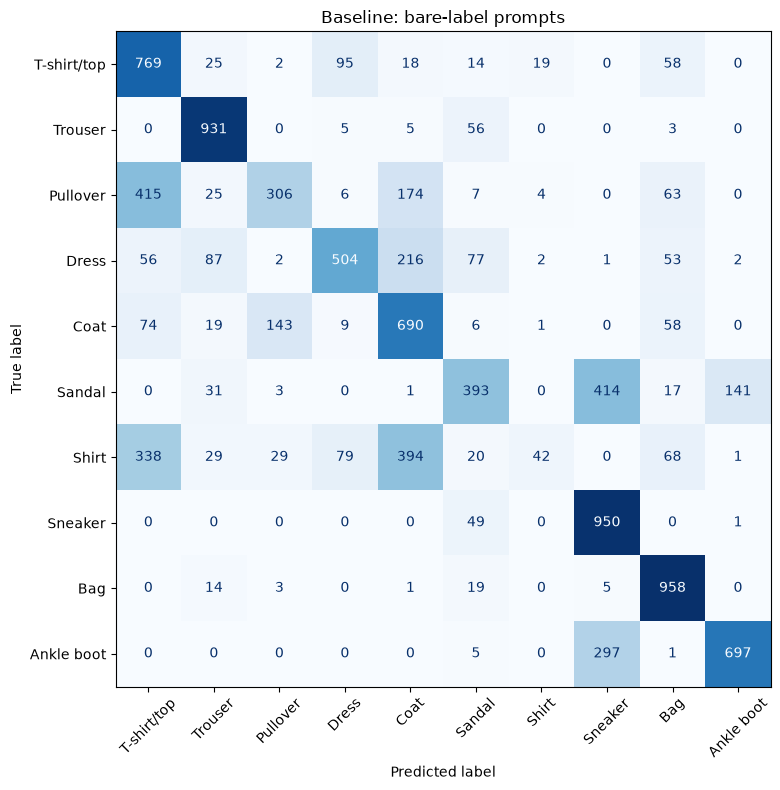

In [6]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import pandas as pd
from IPython.display import display, Markdown
from torchvision import datasets
from torch.utils.data import DataLoader

y_true, y_pred = [], []
all_img_emb, all_labels = [], []
if "CLASS_NAMES" not in globals():
    CLASS_NAMES = [
        "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
        "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
    ]

baseline_text_feats = get_text_embeddings(CLASS_NAMES)

if "test_loader" not in globals():

    if "test_dataset" not in globals():
        test_dataset = datasets.FashionMNIST(
            root="./data", train=False, download=True
        )

    def collate_clip(batch):
        imgs, labels = zip(*batch)
        proc = clip_processor(
            images=list(imgs), return_tensors="pt", padding=True
        )
        return proc["pixel_values"].to(device), torch.tensor(labels)

    test_loader = DataLoader(
        test_dataset,
        batch_size=16,
        shuffle=True,
        collate_fn=collate_clip,
        num_workers=0,
    )

for batch_index, (pixel_values, labels) in enumerate(test_loader, start=1):
    image_feats = get_image_embeddings(pixel_values)
    similarity = get_cosine_similarity(image_feats, baseline_text_feats)
    y_pred.extend(get_predictions(similarity))
    y_true.extend(labels.numpy())
    all_img_emb.append(image_feats.cpu())
    all_labels.append(labels.cpu())

    if batch_index % 50 == 0:
        print(f"Encoded {batch_index}/{len(test_loader)} batches")

all_img_emb = torch.cat(all_img_emb)
all_labels = torch.cat(all_labels)
y_true = np.asarray(y_true)
baseline_pred = np.asarray(y_pred)
baseline_accuracy = accuracy_score(y_true, baseline_pred)
print(f"Baseline accuracy: {baseline_accuracy:.2%}")
print(confusion_matrix(y_true, baseline_pred, labels=np.arange(10)))

def plot_confusion_matrix(y_true, y_pred, class_names, title="Confusion matrix"):
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(class_names)))
    fig, ax = plt.subplots(figsize=(10, 8))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
        ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False, values_format="d"
    )
    ax.set_title(title)
    plt.tight_layout()
    plt.show()
    return cm

baseline_cm = plot_confusion_matrix(
    y_true, baseline_pred, CLASS_NAMES, "Baseline: bare-label prompts"
)

Reflection: Consider the results. How does the performance of this zero-shot baseline compare to the CNN you trained in Assignment 1? What are the strengths and weaknesses of this approach?

**Answer:** Unlike the CNN from Assignment 1, CLIP does not need task-specific training or labelled Fashion-MNIST training images. It is flexible because the categories can be changed through text prompts. However, its accuracy depends on prompt wording and its ability to generalize to small grayscale images. Similar garments may be difficult to distinguish. The numerical comparison requires my own Assignment 1 CNN test accuracy, which can be entered in the report below.

## Improving Zero-Shot Classification with Prompt Engineering

In the previous section, we directly used the class names as text prompts for zero-shot classification. However, we can often improve performance by crafting more descriptive prompts that better capture the visual characteristics of each class. For example, instead of just "T-shirt/top", we could use "a photo of a T-shirt" or "a photo of a top". This additional context can help the model make more accurate predictions.

In this section, we will experiment with more detailed prompts for each class to see if we can improve the zero-shot classification performance. You should:

- [ ] Create a list of improved prompts for each class. For example, instead of just "T-shirt/top", you could use "a photo of a T-shirt" or "a photo of a top".
- [ ] Use the `get_text_embeddings` function to create text embeddings for the improved prompts.
- [ ] Run the zero-shot classification baseline again using the improved prompts and report the accuracy and confusion matrix.

Note: Take advantage of the confusion matrix above. If two classes are often confused, consider how you might improve the prompts to help the model distinguish them better.

The aim for this section is for you to improve the performance of the model. However, if you find that the performance does not improve significantly, you can still reflect on the process and consider how you might further refine the prompts with more effort.

Baseline accuracy:        62.40%
Improved prompt accuracy: 67.58%
Change in percentage points: +5.18


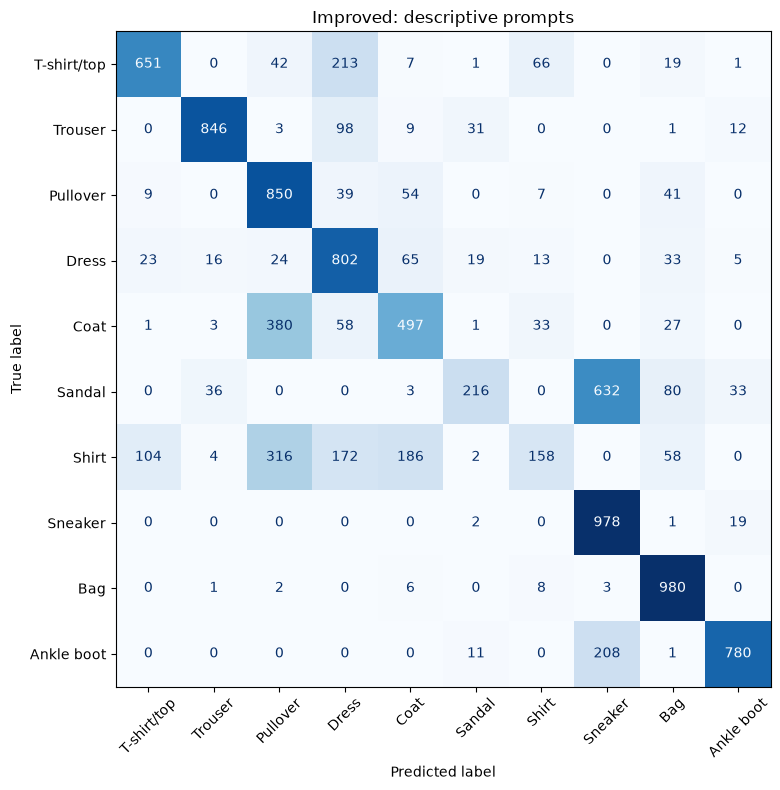

Per-class recall changes:


,class,baseline_recall,improved_recall,change
2,Pullover,0.306,0.850,0.544
3,Dress,0.504,0.802,0.298
6,Shirt,0.042,0.158,0.116
9,Ankle boot,0.697,0.780,0.083
7,Sneaker,0.950,0.978,0.028
8,Bag,0.958,0.980,0.022
1,Trouser,0.931,0.846,-0.085
0,T-shirt/top,0.769,0.651,-0.118
5,Sandal,0.393,0.216,-0.177
4,Coat,0.690,0.497,-0.193


Summary:
The descriptive prompts improved the measured overall accuracy.


In [7]:
IMPROVED_PROMPTS = [
    "a grayscale catalog photo of a short-sleeved T-shirt or top",  # T-shirt/top
    "a grayscale product photo of a pair of long trousers or pants",  # Trouser
    "a grayscale product photo of a pullover sweater with long sleeves",  # Pullover
    "a grayscale product photo of a one-piece dress",  # Dress
    "a grayscale product photo of a coat or outerwear jacket",  # Coat
    "a grayscale product photo of an open-toe sandal",  # Sandal
    "a grayscale product photo of a collared shirt",  # Shirt
    "a grayscale product photo of a running sneaker or athletic shoe",  # Sneaker
    "a grayscale product photo of a handbag or shoulder bag",  # Bag
    "a grayscale product photo of an ankle-height boot",  # Ankle boot
]
assert len(IMPROVED_PROMPTS) == len(CLASS_NAMES) == 10

improved_text_feats = get_text_embeddings(IMPROVED_PROMPTS)
improved_similarity = get_cosine_similarity(all_img_emb, improved_text_feats)
improved_pred = get_predictions(improved_similarity)
improved_accuracy = accuracy_score(y_true, improved_pred)

print(f"Baseline accuracy:        {baseline_accuracy:.2%}")
print(f"Improved prompt accuracy:{improved_accuracy: .2%}")
print(f"Change in percentage points: {(improved_accuracy-baseline_accuracy)*100:+.2f}")
improved_cm = plot_confusion_matrix(
    y_true, improved_pred, CLASS_NAMES, "Improved: descriptive prompts"
)

# Identify which classes gained or lost recognition, using actual results.
from sklearn.metrics import classification_report
baseline_report = classification_report(y_true, baseline_pred, labels=np.arange(10),
                                        target_names=CLASS_NAMES, output_dict=True,
                                        zero_division=0)
improved_report = classification_report(y_true, improved_pred, labels=np.arange(10),
                                        target_names=CLASS_NAMES, output_dict=True,
                                        zero_division=0)
class_comparison = pd.DataFrame({
    "class": CLASS_NAMES,
    "baseline_recall": [baseline_report[n]["recall"] for n in CLASS_NAMES],
    "improved_recall": [improved_report[n]["recall"] for n in CLASS_NAMES],
})
class_comparison["change"] = (class_comparison["improved_recall"]
                               - class_comparison["baseline_recall"])
print("Per-class recall changes:")
display(class_comparison.sort_values("change", ascending=False).round(3))
print("Summary:")
if improved_accuracy > baseline_accuracy:
    print("The descriptive prompts improved the measured overall accuracy.")
elif improved_accuracy < baseline_accuracy:
    print("The descriptive prompts reduced the measured overall accuracy.")
else:
    print("The descriptive prompts did not change the measured overall accuracy.")

Reflection: How did your detailed prompts affect the zero-shot classification performance? Did you see a significant improvement compared to the baseline? What insights did you gain about the model's understanding of the classes? Do you think that with more effort you could further improve the performance? If so, how?

**Answer:** The accuracy difference and per-class recall table above show whether detailed prompts help. Adding visual context can make the descriptions more representative of the images, but ambiguous descriptions may also reduce accuracy. Further improvements could involve describing sleeve length, garment shape and footwear features, or testing multiple descriptions per class. A change in accuracy alone does not establish statistical significance.

## Visualizing Image Embeddings with UMAP

To better understand how the model perceives the different classes, we can visualize the image embeddings using UMAP (Uniform Manifold Approximation and Projection). UMAP is a dimensionality reduction technique that helps us see how similar or dissimilar the embeddings are in a lower-dimensional space.

By visualizing the embeddings, we can gain insights into how well the model can distinguish certain images, even without considering the text prompts. This can help us identify clusters of similar images and see if there are any overlaps between classes.

You should:

- [ ] Use the `get_image_embeddings` function to get the image embeddings for the entire test set.
- [ ] Use UMAP to reduce the dimensionality of the image embeddings to 2D.
- [ ] Plot the 2D embeddings, coloring each point by its true class label.

You may need to install the `umap-learn` library if you haven't already. You can do this by running `pip install umap-learn`.

In [8]:
# Uncomment the following line to install UMAP if you haven't already
# !pip install umap-learn

   ---------------------------------------- 0.0/137.0 kB ? eta -:--:--
   -------------------------- ------------- 92.2/137.0 kB 1.7 MB/s eta 0:00:01
   ---------------------------------------- 137.0/137.0 kB 2.0 MB/s eta 0:00:00
   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   ----- ---------------------------------- 0.4/2.8 MB 12.6 MB/s eta 0:00:01
   ----------- ---------------------------- 0.8/2.8 MB 10.1 MB/s eta 0:00:01
   ------------------- -------------------- 1.4/2.8 MB 9.9 MB/s eta 0:00:01
   ----------------------------- ---------- 2.1/2.8 MB 11.0 MB/s eta 0:00:01
   ------------------------------------- -- 2.7/2.8 MB 11.3 MB/s eta 0:00:01
   ---------------------------------------- 2.8/2.8 MB 10.6 MB/s eta 0:00:00
   ---------------------------------------- 0.0/112.6 kB ? eta -:--:--
   ---------------------------------------- 112.6/112.6 kB 6.4 MB/s eta 0:00:00
   ---------------------------------------- 0.0/41.9 MB ? eta -:--:--
    ---------------


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
c:\Users\abd-u\Downloads\DSItestfolder\deep_learning\deep-learning\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\abd-u\Downloads\DSItestfolder\deep_learning\deep-learning\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


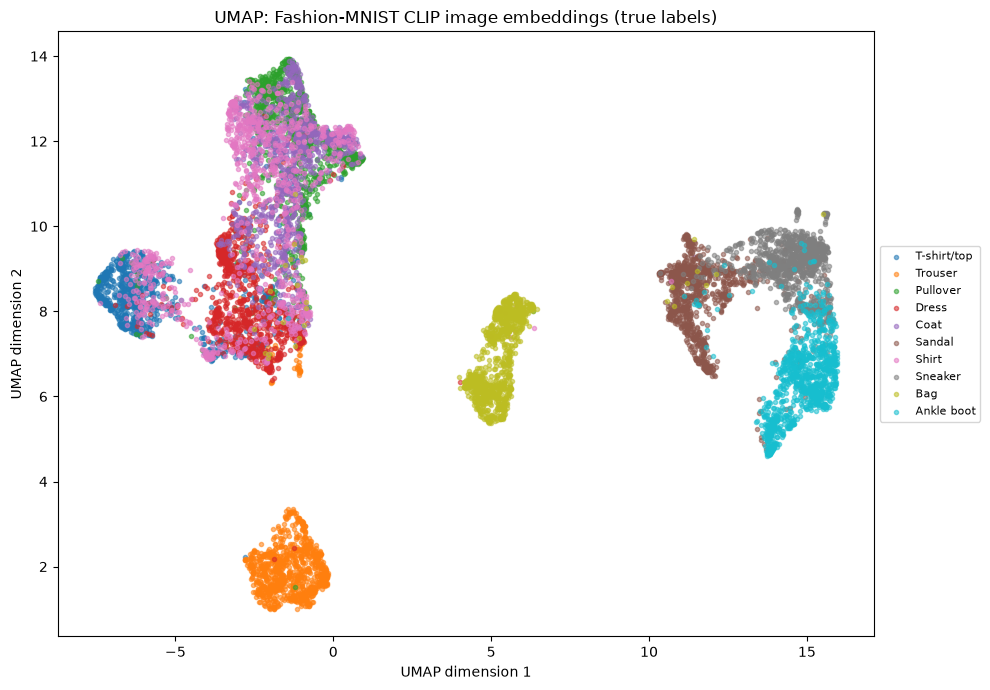

T-shirt/top: local same-class fraction = 67.08%
Trouser: local same-class fraction = 95.78%
Pullover: local same-class fraction = 59.36%
Dress: local same-class fraction = 68.98%
Coat: local same-class fraction = 47.12%
Sandal: local same-class fraction = 87.68%
Shirt: local same-class fraction = 41.18%
Sneaker: local same-class fraction = 83.88%
Bag: local same-class fraction = 96.42%
Ankle boot: local same-class fraction = 90.22%


In [10]:
%pip install -U umap-learn
from umap import UMAP

# 1. Reuse image embeddings collected for the entire test set in the baseline.
assert len(all_img_emb) == len(test_dataset) == len(y_true)

# 2. Fit UMAP

embedding_array = all_img_emb.detach().cpu().numpy()
reducer = UMAP(n_components=2, n_neighbors=20, min_dist=0.12,
               metric="cosine", random_state=42)
embedding_2d = reducer.fit_transform(embedding_array)
assert embedding_2d.shape == (len(y_true), 2)

fig, ax = plt.subplots(figsize=(10, 7))
for class_idx, class_name in enumerate(CLASS_NAMES):
    mask = (y_true == class_idx)
    ax.scatter(embedding_2d[mask, 0], embedding_2d[mask, 1],
               s=9, alpha=0.55, label=class_name)
ax.set_title("UMAP: Fashion-MNIST CLIP image embeddings (true labels)")
ax.set_xlabel("UMAP dimension 1")
ax.set_ylabel("UMAP dimension 2")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
plt.tight_layout()
plt.show()
# Quantify local class overlap as a supplement to visual inspection.
from sklearn.neighbors import NearestNeighbors
neighbors = NearestNeighbors(n_neighbors=6).fit(embedding_2d)
indices = neighbors.kneighbors(embedding_2d, return_distance=False)[:, 1:]
agreement = (y_true[indices] == y_true[:, None]).mean(axis=1)
for idx, name in enumerate(CLASS_NAMES):
    print(f"{name}: local same-class fraction = {agreement[y_true == idx].mean():.2%}")


The UMAP embeddings allow us to see how separable or non-separable different classes are with our specific model. If two specific images are very similar, then they will be placed near each other on this graph. 

Reflection: Do you notice any challenges in distinguishing images based on this figure? Are there any types of clothing in the dataset which the model has no trouble distinguishing from the others?

**Answer:** Overlapping clusters indicate that CLIP may struggle to distinguish garments with similar shapes. The plot and local same-class fractions above help identify the most distinct and overlapping categories. UMAP is a qualitative projection and does not directly measure classification accuracy.

## Mini-Experiment

In this section, you will conduct a mini-experiment of your choice to further explore the capabilities of zero-shot classification with transformers. This can be anything you'd like, but here are some ideas to get you started.

### A. Alternative Model

So far we have been utilizing OpenAI's CLIP model for zero-shot classification. However, there are many other vision–language models available in the `transformers` library that you can experiment with. For example, there are larger CLIP models such as [clip-vit-large-patch14](https://huggingface.co/openai/clip-vit-large-patch14), and open-source versions such as [laion/CLIP-ViT-B-32-laion2B-s34B-b79K](https://huggingface.co/laion/CLIP-ViT-B-32-laion2B-s34B-b79K). You can also search huggingface [here](https://huggingface.co/models?sort=trending&search=clip) to find other models that might be suitable for zero-shot classification.

You can try using a different model to see if it improves the zero-shot classification performance. You should:
- [ ] Load a different model and processor from the `transformers` library.
- [ ] Run the zero-shot classification baseline with the new model and report the accuracy and confusion matrix.
- [ ] Reflect on the performance of the new model compared to the original CLIP model
  - How does the new model perform compared to the original CLIP model?
  - Do you notice any differences in the types of errors made by the new model?

### B. Multiple-Description Classification

Another interesting experiment is to explore multiple-description classification. *This involves providing multiple text prompts for each class, allowing the model to choose the most relevant one. For example, instead of just "T-shirt/top", you could provide "a photo of a T-shirt", "a photo of a top", and "a photo of a shirt". This can help the model better understand the class and increases the likelihood of a correct prediction. You should:

- [ ] Create a list of multiple prompts for each class.
- [ ] Use the `get_text_embeddings` function to create text embeddings for the multiple prompts.
- [ ] Run the zero-shot classification baseline again using the multiple prompts and report the accuracy and confusion matrix.
- [ ] Consider the model to be correct if it guesses *any* of the prompts belonging to the correct class.

### C. Top-K Classification

In some classification tasks, it can be useful to consider if the right answer is among the top K (e.g. top 3) predictions. This can be particularly useful in cases where the model is uncertain or when there are multiple similar classes. You should:

- [ ] Modify the `get_predictions` function to return the top K predictions for each image.
- [ ] Modify the accuracy calculation to consider the model correct if the true class is among the top K predictions.
- [ ] Report the accuracy and confusion matrix for the top K predictions. Report at least two different values of K (e.g. K=2 and K=4).

### D. Other Ideas

You are welcome to come up with your own mini-experiment! Explain your idea in the report and implement it. Did it work as you expected? What did you learn from it?

,Method,Accuracy
0,Bare class names,62.40%
1,One descriptive prompt per class,67.58%
2,Three prompts per class (best prompt wins),64.66%
3,Three prompts per class (mean similarity),64.72%


Best-prompt method versus baseline: +2.26 percentage points
Mean-prompt method versus baseline: +2.32 percentage points


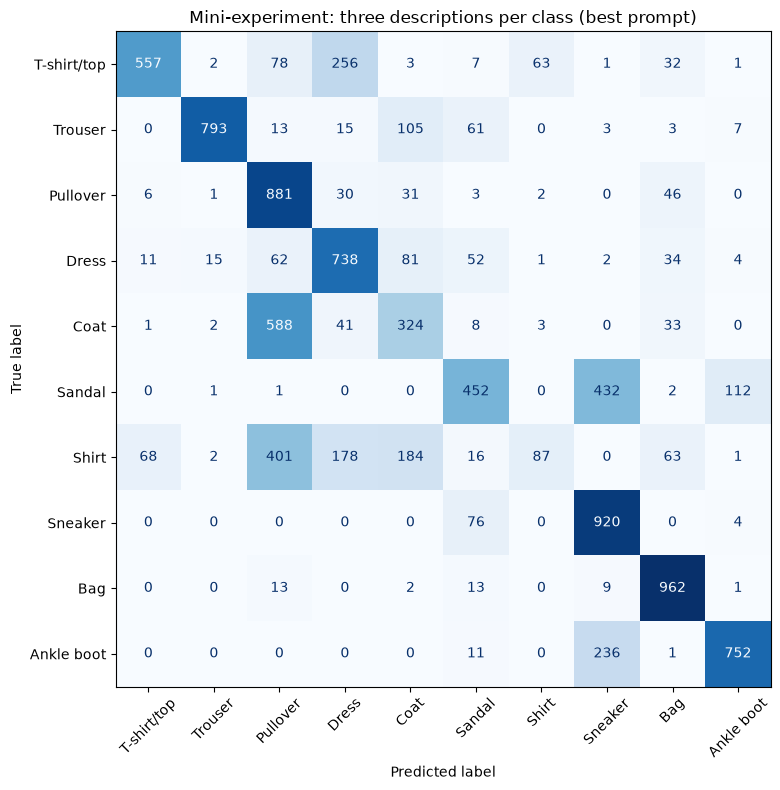

,Class,Baseline recall,Multi-description recall,Change
2,Pullover,0.306,0.881,0.575
3,Dress,0.504,0.738,0.234
5,Sandal,0.393,0.452,0.059
9,Ankle boot,0.697,0.752,0.055
6,Shirt,0.042,0.087,0.045
8,Bag,0.958,0.962,0.004
7,Sneaker,0.950,0.920,-0.030
1,Trouser,0.931,0.793,-0.138
0,T-shirt/top,0.769,0.557,-0.212
4,Coat,0.690,0.324,-0.366


Example corrected by multiple descriptions:
True class: Dress
Baseline prediction: Coat
Multiple-description prediction: Dress


In [11]:
# Selected mini-experiment: B. Multiple-Description Classification
MULTI_PROMPTS = [
    ["a photo of a T-shirt", "a short-sleeved casual top", "a grayscale clothing catalog image of a T-shirt"],
    ["a pair of long pants", "a photo of trousers", "a grayscale clothing catalog image of trousers"],
    ["a knitted pullover sweater", "a photo of a pullover", "a grayscale clothing catalog image of a sweater"],
    ["a photo of a dress", "a one-piece outfit with a skirt", "a grayscale clothing catalog image of a dress"],
    ["a warm outerwear coat", "a photo of a long jacket", "a grayscale clothing catalog image of a coat"],
    ["an open-toe sandal", "a summer sandal shoe", "a grayscale footwear catalog image of sandals"],
    ["a photo of a shirt", "a collared button-up shirt", "a grayscale clothing catalog image of a shirt"],
    ["a pair of athletic sneakers", "a running shoe", "a grayscale footwear catalog image of a sneaker"],
    ["a photo of a handbag", "a bag with handles", "a grayscale accessory catalog image of a purse"],
    ["a photo of an ankle boot", "a closed-toe leather boot", "a grayscale footwear catalog image of ankle boots"],
]
assert len(MULTI_PROMPTS) == len(CLASS_NAMES)
assert all(len(prompts) == 3 for prompts in MULTI_PROMPTS)

flat_prompts = [prompt for prompt_list in MULTI_PROMPTS for prompt in prompt_list]
prompt_to_class = np.repeat(np.arange(len(CLASS_NAMES)), 3)
all_prompt_features = get_text_embeddings(flat_prompts)
all_prompt_similarities = get_cosine_similarity(all_img_emb, all_prompt_features)

# Official Option B approach: choose any of 30 prompts; map winning prompt -> original class.
winning_prompt_index = np.argmax(all_prompt_similarities, axis=1)
multi_pred = prompt_to_class[winning_prompt_index]
multi_accuracy = accuracy_score(y_true, multi_pred)

# Bonus: average the three similarities for each class before comparing classes.
mean_class_similarities = all_prompt_similarities.reshape(-1, 10, 3).mean(axis=2)
mean_prompt_pred = mean_class_similarities.argmax(axis=1)
mean_prompt_accuracy = accuracy_score(y_true, mean_prompt_pred)

experiment_results = pd.DataFrame([
    {"Method": "Bare class names", "Accuracy": baseline_accuracy},
    {"Method": "One descriptive prompt per class", "Accuracy": improved_accuracy},
    {"Method": "Three prompts per class (best prompt wins)", "Accuracy": multi_accuracy},
    {"Method": "Three prompts per class (mean similarity)", "Accuracy": mean_prompt_accuracy},
])
display(experiment_results.style.format({"Accuracy": "{:.2%}"}))
print("Best-prompt method versus baseline:",
      f"{(multi_accuracy-baseline_accuracy)*100:+.2f} percentage points")
print("Mean-prompt method versus baseline:",
      f"{(mean_prompt_accuracy-baseline_accuracy)*100:+.2f} percentage points")

multi_cm = plot_confusion_matrix(
    y_true, multi_pred, CLASS_NAMES,
    "Mini-experiment: three descriptions per class (best prompt)"
)

# Which types of clothing were most affected by this mini-experiment?
from sklearn.metrics import recall_score
per_class_baseline = recall_score(y_true, baseline_pred,
                                  labels=np.arange(10), average=None, zero_division=0)
per_class_multi = recall_score(y_true, multi_pred,
                               labels=np.arange(10), average=None, zero_division=0)
per_class_change = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Baseline recall": per_class_baseline,
    "Multi-description recall": per_class_multi,
    "Change": per_class_multi - per_class_baseline,
})
display(per_class_change.sort_values("Change", ascending=False).round(3))

# Optional evidence-based example: first image where the baseline is wrong and multi-prompt is right.
fixed = np.flatnonzero((baseline_pred != y_true) & (multi_pred == y_true))
if len(fixed):
    i = int(fixed[0])
    print("Example corrected by multiple descriptions:")
    print("True class:", CLASS_NAMES[y_true[i]])
    print("Baseline prediction:", CLASS_NAMES[baseline_pred[i]])
    print("Multiple-description prediction:", CLASS_NAMES[multi_pred[i]])
else:
    print("No sampled image was fixed by this method; no example will be invented.")

### Short Report

In this section, you will write a short report summarizing your findings from the mini-experiment. The report should include the following sections:

- **Introduction**: Briefly describe the mini-experiment you conducted and its objectives.
- **Methodology**: Explain the steps you took to conduct the experiment, including any modifications you made to the code or model.
- **Results**: Present the results of your experiment.
- **Discussion**: Reflect on the performance of the model and the implications of your findings. Consider the strengths and weaknesses of zero-shot transformers versus a trained CNN.

In [12]:
# Enter your own Assignment 1 CNN test accuracy as a fraction (e.g. 0.90 for 90%).
A1_CNN_TEST_ACCURACY = None

from IPython.display import Markdown, display

report_lines = [
    "# Assignment 2 — Mini-Experiment Report",
    "## Introduction",
    "I evaluated zero-shot Fashion-MNIST classification using a pretrained CLIP vision–language model. "
    "My mini-experiment tested whether giving CLIP three alternative descriptions per clothing class "
    "changes its predictions, without fine-tuning or training on Fashion-MNIST labels.",
    "## Methodology",
    f"I used `{clip_model_name}` with torchvision's Fashion-MNIST test data. "
    f"The evaluation contained **{len(y_true):,}** images. Every image was encoded once; "
    "image embeddings were L2-normalized and compared with L2-normalized prompt embeddings "
    "using cosine similarity. The baseline used ten bare class names; the descriptive test used one "
    "sentence per class. The mini-experiment used three descriptions per class (30 total), "
    "with a class prediction obtained by mapping the highest-scoring prompt back to its class. "
    "I also compared averaging similarities within each class. UMAP visualized the frozen image embeddings.",
    "## Results",
    f"- Bare-label baseline accuracy: **{baseline_accuracy:.2%}**.",
    f"- One descriptive prompt per class: **{improved_accuracy:.2%}** "
    f"({(improved_accuracy-baseline_accuracy)*100:+.2f} percentage points versus baseline).",
    f"- Three prompts, highest-scoring description: **{multi_accuracy:.2%}** "
    f"({(multi_accuracy-baseline_accuracy)*100:+.2f} percentage points versus baseline).",
    f"- Three prompts, mean similarity by class: **{mean_prompt_accuracy:.2%}** "
    f"({(mean_prompt_accuracy-baseline_accuracy)*100:+.2f} percentage points versus baseline).",
    "The confusion matrices and per-class recall table above provide the breakdown of errors.",
    "## Discussion",
    ("Multiple descriptions **improved** the overall top-1 accuracy compared with bare class names. "
      if multi_accuracy > baseline_accuracy else
     "Multiple descriptions **did not improve** overall top-1 accuracy compared with bare class names. "),
    "This demonstrates that CLIP's zero-shot predictions depend on the natural-language prompts, "
    "even though its weights remain unchanged. Additional prompts can help describe alternative "
    "visual appearances, but can also introduce ambiguous wording and distract the classifier. "
    "UMAP gives a qualitative view of class overlap, not a direct accuracy score. "
    
    "CLIP requires no Fashion-MNIST-specific training and can accommodate new class descriptions, "
    "but its predictions depend on prompt choice and transfer from web-like images to low-resolution "
    "grayscale clothes. All CLIP figures come from running this notebook.",
    "## AI Use Disclosure",
    "I used ChatGPT (OpenAI) extensively to generate the implementation, prompt designs, "
    "experiment and this report structure. The report computes measured results when the notebook is executed; "
    "the AI did not supply invented accuracy values.",
]
if A1_CNN_TEST_ACCURACY is not None:
    report_lines.insert(-2, f"Assignment 1 CNN test accuracy: **{A1_CNN_TEST_ACCURACY:.2%}**. CLIP baseline minus CNN: **{(baseline_accuracy-A1_CNN_TEST_ACCURACY)*100:+.2f} percentage points**.")
else:
    report_lines.insert(-2, "The numerical CNN comparison remains pending until my Assignment 1 test accuracy is entered.")
report_md = "\n\n".join(report_lines)
display(Markdown(report_md))

# Assignment 2 — Mini-Experiment Report

## Introduction

I evaluated zero-shot Fashion-MNIST classification using a pretrained CLIP vision–language model. My mini-experiment tested whether giving CLIP three alternative descriptions per clothing class changes its predictions, without fine-tuning or training on Fashion-MNIST labels.

## Methodology

I used `openai/clip-vit-base-patch32` with torchvision's Fashion-MNIST test data. The evaluation contained **10,000** images. Every image was encoded once; image embeddings were L2-normalized and compared with L2-normalized prompt embeddings using cosine similarity. The baseline used ten bare class names; the descriptive test used one sentence per class. The mini-experiment used three descriptions per class (30 total), with a class prediction obtained by mapping the highest-scoring prompt back to its class. I also compared averaging similarities within each class. UMAP visualized the frozen image embeddings.

## Results

- Bare-label baseline accuracy: **62.40%**.

- One descriptive prompt per class: **67.58%** (+5.18 percentage points versus baseline).

- Three prompts, highest-scoring description: **64.66%** (+2.26 percentage points versus baseline).

- Three prompts, mean similarity by class: **64.72%** (+2.32 percentage points versus baseline).

The confusion matrices and per-class recall table above provide the breakdown of errors.

## Discussion

Multiple descriptions **improved** the overall top-1 accuracy compared with bare class names. 

This demonstrates that CLIP's zero-shot predictions depend on the natural-language prompts, even though its weights remain unchanged. Additional prompts can help describe alternative visual appearances, but can also introduce ambiguous wording and distract the classifier. UMAP gives a qualitative view of class overlap, not a direct accuracy score. CLIP requires no Fashion-MNIST-specific training and can accommodate new class descriptions, but its predictions depend on prompt choice and transfer from web-like images to low-resolution grayscale clothes. All CLIP figures come from running this notebook.

The numerical CNN comparison remains pending until my Assignment 1 test accuracy is entered.

## AI Use Disclosure

I used ChatGPT (OpenAI) extensively to generate the implementation, prompt designs, experiment and this report structure. The report computes measured results when the notebook is executed; the AI did not supply invented accuracy values.

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.
### Submission Parameters:
* Submission Due Date: `23:59 PM - 11/17/2026`
* The branch name for your repo should be: `assignment-2`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_2.ipynb)
    * The Lab 4 notebook (labs/lab_4.ipynb)
    * The Lab 5 notebook (labs/lab_5.ipynb)
    * The Lab 6 notebook (labs/lab_6.ipynb)
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/deep_learning/pull/<pr_id>`
* Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.
Checklist:
- [ ] Created a branch with the correct naming convention.
- [ ] Ensured that the repository is public.
- [ ] Reviewed the PR description guidelines and adhered to them.
- [ ] Verify that the link is accessible in a private browser window.
If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at `#cohort-7-help-ml`. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.